# Wprowadzenie do uczenia maszynowego - Lista 2
Konrad Słotta 277442

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import os
import pandas as pd
from sklearn.datasets import make_blobs

## Zadanie 1

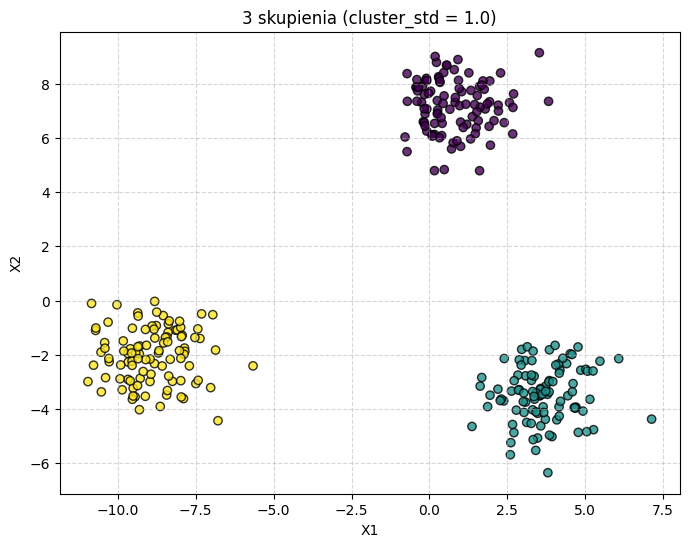

In [2]:
X, y = make_blobs(
    n_samples=300,
    centers=3,
    n_features=2,
    cluster_std=1.0,
    random_state=67
)

plt.figure(figsize=(8, 6))
scatter = plt.scatter(
    X[:, 0], 
    X[:, 1], 
    c=y, 
    edgecolor='k', 
    alpha=0.8
)

plt.xlabel('X1')
plt.ylabel('X2')
plt.title('3 skupienia (cluster_std = 1.0)')
plt.grid(True, linestyle='--', alpha=0.5)

plt.show()

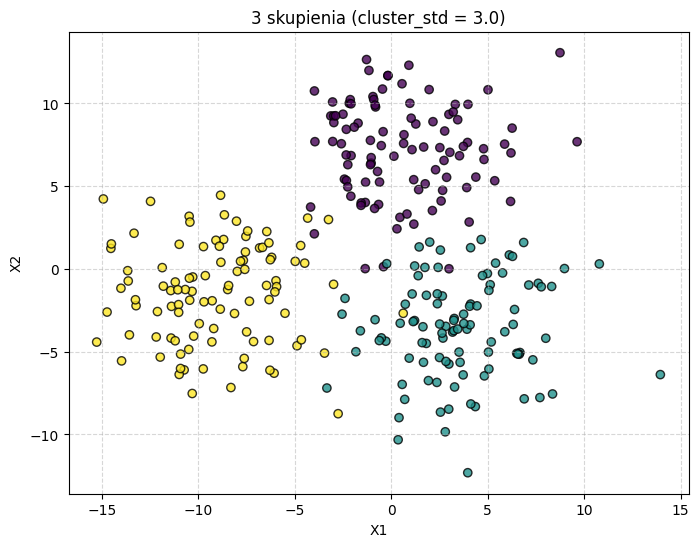

In [3]:
X2, y2 = make_blobs(
    n_samples=300,
    centers=3,
    n_features=2,
    cluster_std=3.0,
    random_state=67
)

plt.figure(figsize=(8, 6))
scatter = plt.scatter(
    X2[:, 0], 
    X2[:, 1], 
    c=y2, 
    edgecolor='k', 
    alpha=0.8
)

plt.xlabel('X1')
plt.ylabel('X2')
plt.title('3 skupienia (cluster_std = 3.0)')
plt.grid(True, linestyle='--', alpha=0.5)

plt.show()

## Zadanie 2

In [4]:
class CustomKMeans:
    def __init__(self, k=3, max_iter=100, tol=1e-4, random_state=67):
        self.k = k
        self.max_iter = max_iter
        self.tol = tol
        self.random_state = random_state
        self.centroids = None
        self.labels = None

    def fit(self, X):
        np.random.seed(self.random_state)
        n_samples, n_features = X.shape

        random_indices = np.random.choice(n_samples, self.k, replace=False)
        self.centroids = X[random_indices].copy()

        for iteration in range(self.max_iter):
            distances = np.linalg.norm(X[:, np.newaxis] - self.centroids, axis=2)
            self.labels = np.argmin(distances, axis=1)

            new_centroids = np.zeros_like(self.centroids)
            for j in range(self.k):
                cluster_points = X[self.labels == j]
                if len(cluster_points) > 0:
                    new_centroids[j] = cluster_points.mean(axis=0)
                else:
                    new_centroids[j] = self.centroids[j]

            centroid_shift = np.linalg.norm(new_centroids - self.centroids)
            self.centroids = new_centroids

            if centroid_shift < self.tol:
                #print(f"Zbieżność osiągnięta w iteracji {iteration + 1}")
                break

        return self

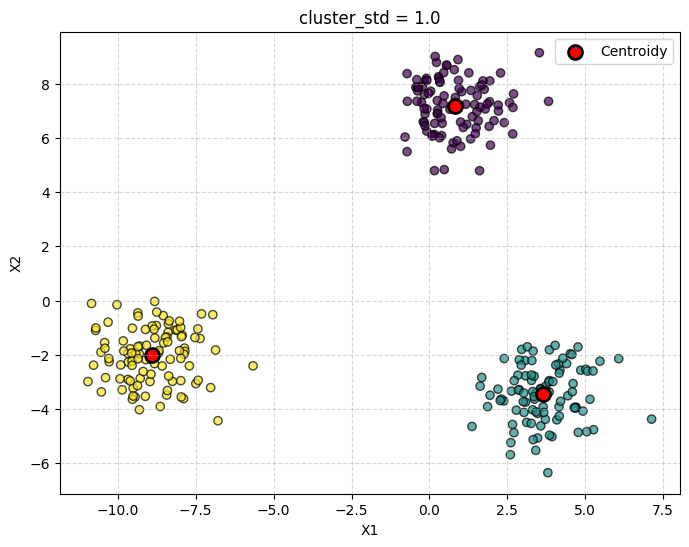

In [5]:
kmeans = CustomKMeans(k=3, random_state=67)
kmeans.fit(X)

plt.figure(figsize=(8, 6))

scatter = plt.scatter(
    X[:, 0], 
    X[:, 1], 
    c=kmeans.labels, 
    cmap='viridis', 
    alpha=0.7, 
    edgecolor='k',
)

plt.scatter(
    kmeans.centroids[:, 0], 
    kmeans.centroids[:, 1], 
    c='red',  
    s=100, 
    linewidths=2, 
    edgecolor='black', 
    label='Centroidy'
)

plt.xlabel('X1')
plt.ylabel('X2')
plt.title('cluster_std = 1.0')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)

plt.show()

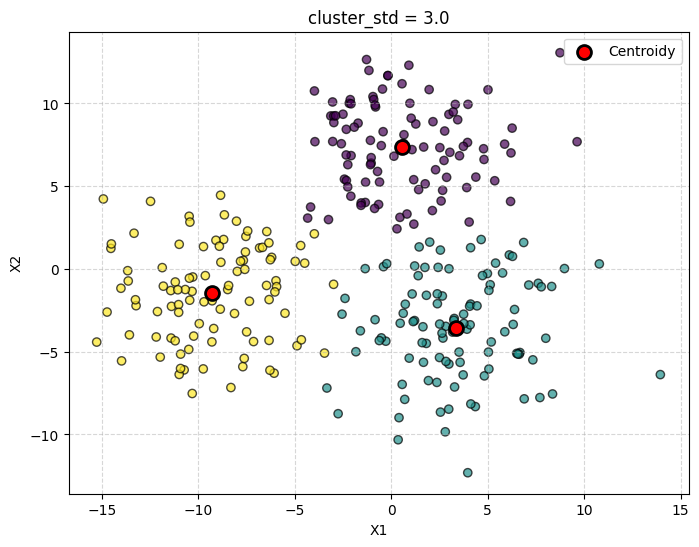

In [6]:
kmeans2 = CustomKMeans(k=3, random_state=67)
kmeans2.fit(X2)

plt.figure(figsize=(8, 6))

scatter = plt.scatter(
    X2[:, 0], 
    X2[:, 1], 
    c=kmeans2.labels, 
    cmap='viridis', 
    alpha=0.7, 
    edgecolor='k',
)

plt.scatter(
    kmeans2.centroids[:, 0], 
    kmeans2.centroids[:, 1], 
    c='red',  
    s=100, 
    linewidths=2, 
    edgecolor='black', 
    label='Centroidy'
)

plt.xlabel('X1')
plt.ylabel('X2')
plt.title('cluster_std = 3.0')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)

plt.show()

## Zadanie 3

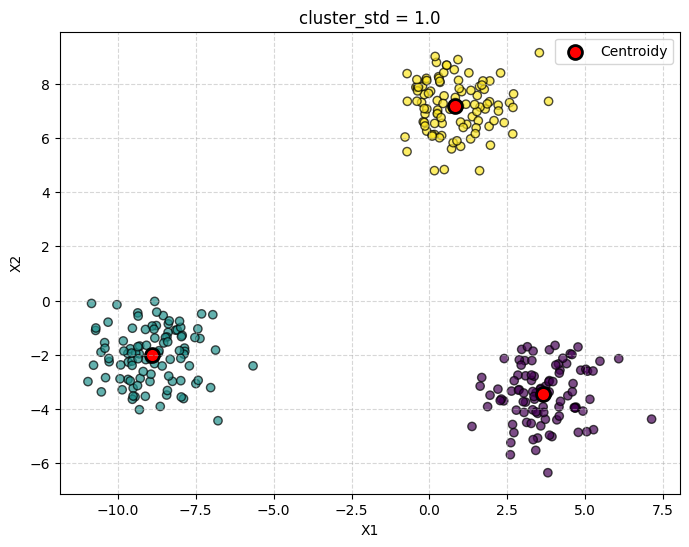

In [7]:
from sklearn.cluster import KMeans

kmeans = KMeans(n_clusters=3, random_state=67, n_init=10)
labels = kmeans.fit_predict(X)
centroids = kmeans.cluster_centers_

plt.figure(figsize=(8, 6))

scatter = plt.scatter(
    X[:, 0], 
    X[:, 1], 
    c=labels, 
    cmap='viridis', 
    alpha=0.7, 
    edgecolor='k'
)

plt.scatter(
    centroids[:, 0], 
    centroids[:, 1], 
    c='red', 
    s=100, 
    linewidths=2, 
    edgecolor='black', 
    label='Centroidy'
)

plt.xlabel('X1')
plt.ylabel('X2')
plt.title('cluster_std = 1.0')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)

plt.show()

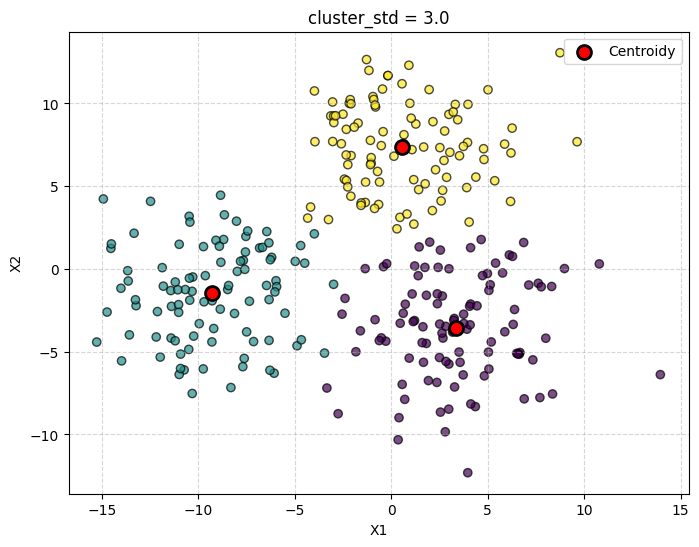

In [8]:
kmeans2 = KMeans(n_clusters=3, random_state=67, n_init=10)
labels = kmeans2.fit_predict(X2)
centroids = kmeans2.cluster_centers_

plt.figure(figsize=(8, 6))

scatter = plt.scatter(
    X2[:, 0], 
    X2[:, 1], 
    c=labels, 
    cmap='viridis', 
    alpha=0.7, 
    edgecolor='k'
)

plt.scatter(
    centroids[:, 0], 
    centroids[:, 1], 
    c='red', 
    s=100, 
    linewidths=2, 
    edgecolor='black', 
    label='Centroidy'
)

plt.xlabel('X1')
plt.ylabel('X2')
plt.title('cluster_std = 3.0')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)

plt.show()

## Zadanie 4

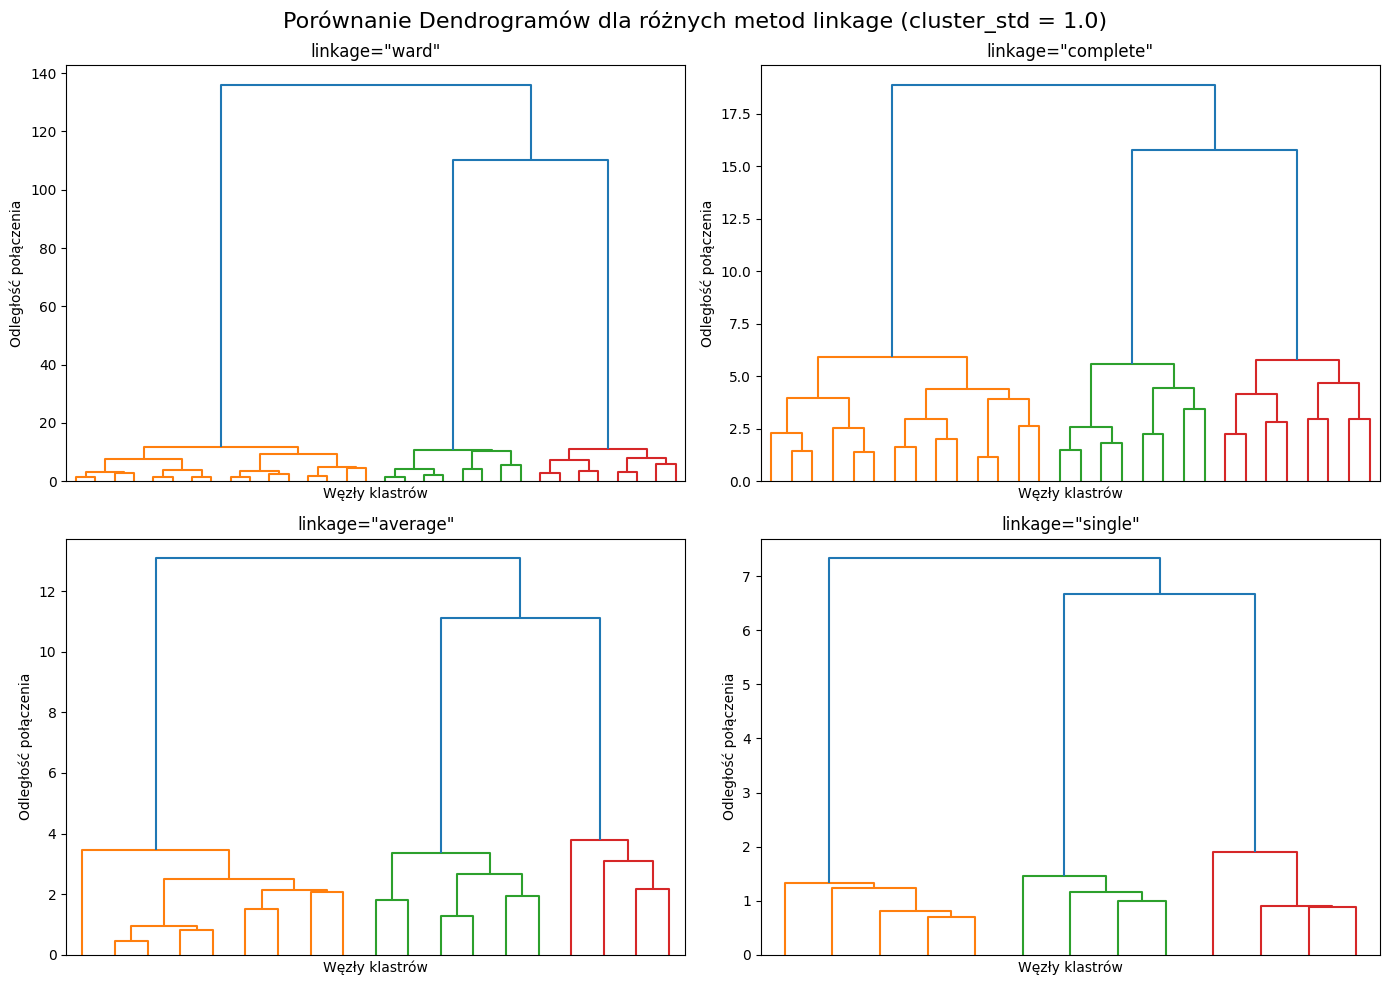

In [9]:
from sklearn.cluster import AgglomerativeClustering
from scipy.cluster.hierarchy import dendrogram, linkage

linkage_methods = ['ward', 'complete', 'average', 'single']

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
axes = axes.ravel()

for i, method in enumerate(linkage_methods):
    Z = linkage(X, method=method)
    
    dendrogram(Z, ax=axes[i], truncate_mode='level', p=4, no_labels=True)
    axes[i].set_title(f'linkage="{method}"')
    axes[i].set_xlabel('Węzły klastrów')
    axes[i].set_ylabel('Odległość połączenia')

plt.suptitle('Porównanie Dendrogramów dla różnych metod linkage (cluster_std = 1.0)', fontsize=16)
plt.tight_layout()
plt.show()

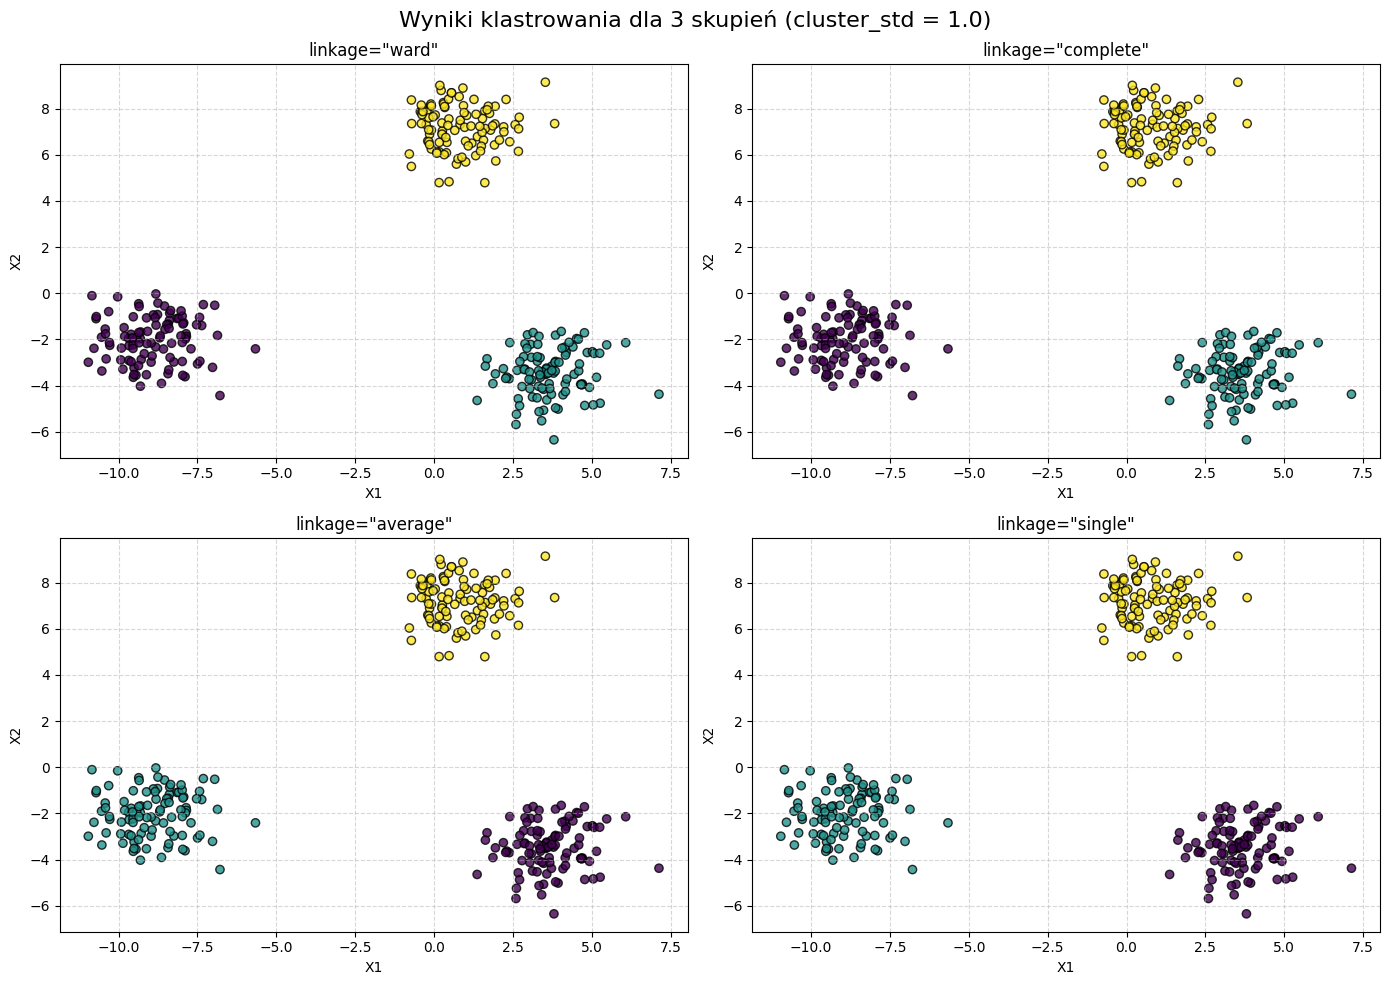

In [10]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
axes = axes.ravel()

for i, method in enumerate(linkage_methods):
    model = AgglomerativeClustering(n_clusters=3, linkage=method)
    labels = model.fit_predict(X)
    
    axes[i].scatter(X[:, 0], X[:, 1], c=labels, cmap='viridis', alpha=0.8, edgecolor='k')
    axes[i].set_title(f'linkage="{method}"')
    axes[i].set_xlabel('X1')
    axes[i].set_ylabel('X2')
    axes[i].grid(True, linestyle='--', alpha=0.5)

plt.suptitle('Wyniki klastrowania dla 3 skupień (cluster_std = 1.0)', fontsize=16)
plt.tight_layout()
plt.show()

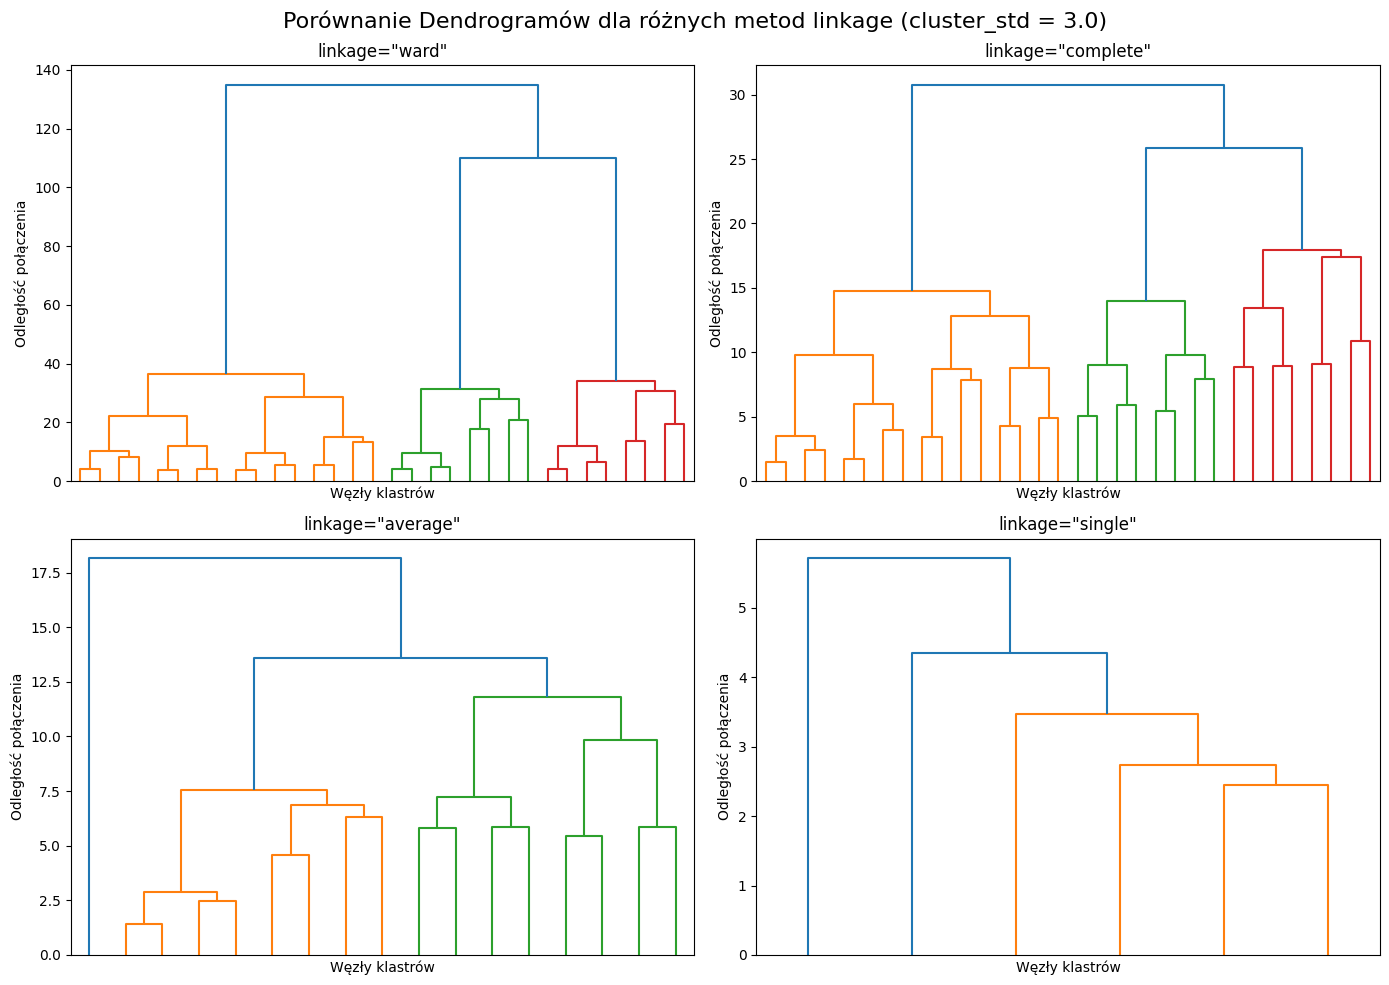

In [11]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
axes = axes.ravel()

for i, method in enumerate(linkage_methods):
    Z2 = linkage(X2, method=method)
    
    dendrogram(Z2, ax=axes[i], truncate_mode='level', p=4, no_labels=True)
    axes[i].set_title(f'linkage="{method}"')
    axes[i].set_xlabel('Węzły klastrów')
    axes[i].set_ylabel('Odległość połączenia')

plt.suptitle('Porównanie Dendrogramów dla różnych metod linkage (cluster_std = 3.0)', fontsize=16)
plt.tight_layout()
plt.show()

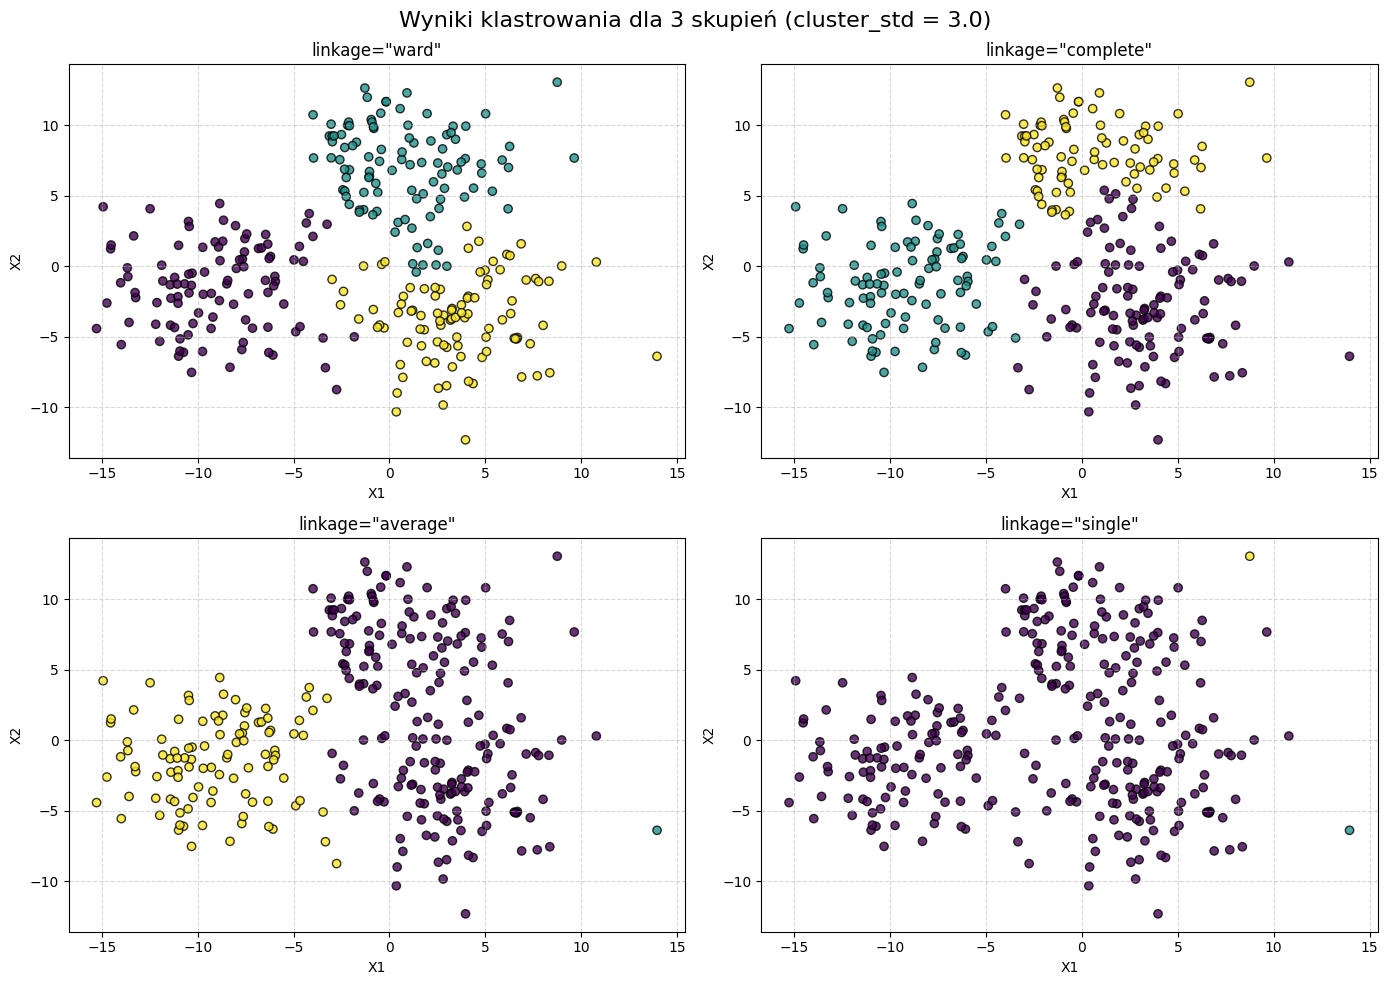

In [12]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
axes = axes.ravel()

for i, method in enumerate(linkage_methods):
    model = AgglomerativeClustering(n_clusters=3, linkage=method)
    labels = model.fit_predict(X2)
    
    axes[i].scatter(X2[:, 0], X2[:, 1], c=labels, cmap='viridis', alpha=0.8, edgecolor='k')
    axes[i].set_title(f'linkage="{method}"')
    axes[i].set_xlabel('X1')
    axes[i].set_ylabel('X2')
    axes[i].grid(True, linestyle='--', alpha=0.5)

plt.suptitle('Wyniki klastrowania dla 3 skupień (cluster_std = 3.0)', fontsize=16)
plt.tight_layout()
plt.show()

## Zadanie 5

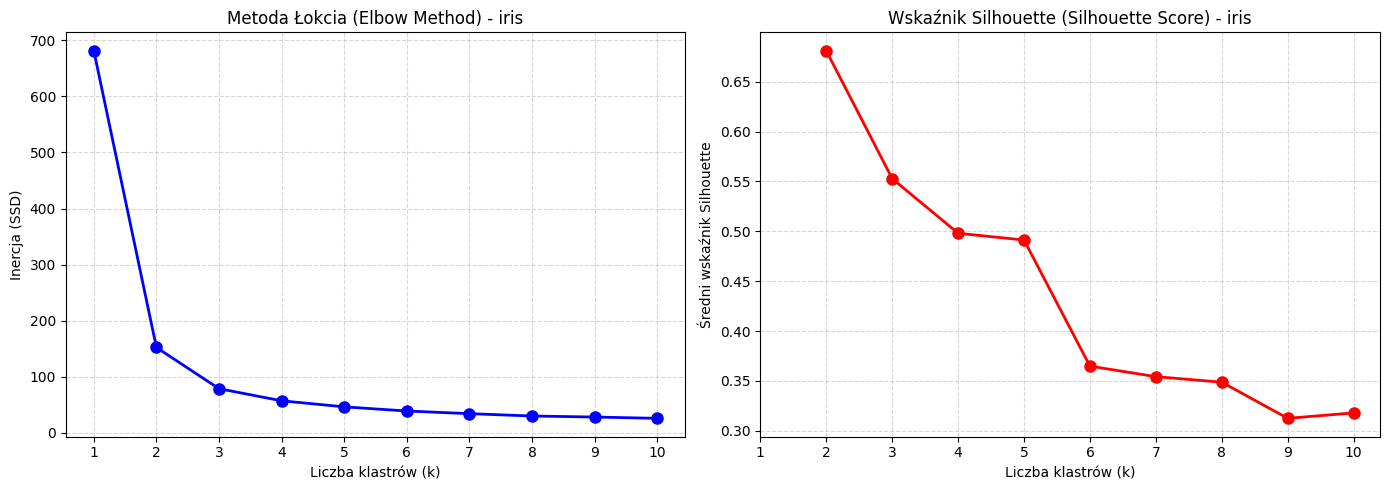

In [13]:
from sklearn.datasets import load_iris
from sklearn.metrics import silhouette_score

iris = load_iris()
X_iris = iris.data

k_range = range(1, 11)
inertia_list = []
silhouette_list = []

for k in k_range:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = kmeans.fit_predict(X_iris)
    inertia_list.append(kmeans.inertia_)
    if k > 1:
        silhouette_list.append(silhouette_score(X_iris, labels))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(k_range, inertia_list, 'bo-', linewidth=2, markersize=8)
axes[0].set_title('Metoda Łokcia (Elbow Method) - iris')
axes[0].set_xlabel('Liczba klastrów (k)')
axes[0].set_ylabel('Inercja (SSD)')
axes[0].grid(True, linestyle='--', alpha=0.5)
axes[0].set_xticks(k_range)

axes[1].plot(k_range[1:], silhouette_list, 'ro-', linewidth=2, markersize=8)
axes[1].set_title('Wskaźnik Silhouette (Silhouette Score) - iris')
axes[1].set_xlabel('Liczba klastrów (k)')
axes[1].set_ylabel('Średni wskaźnik Silhouette')
axes[1].grid(True, linestyle='--', alpha=0.5)
axes[1].set_xticks(k_range)

plt.tight_layout()
plt.show()

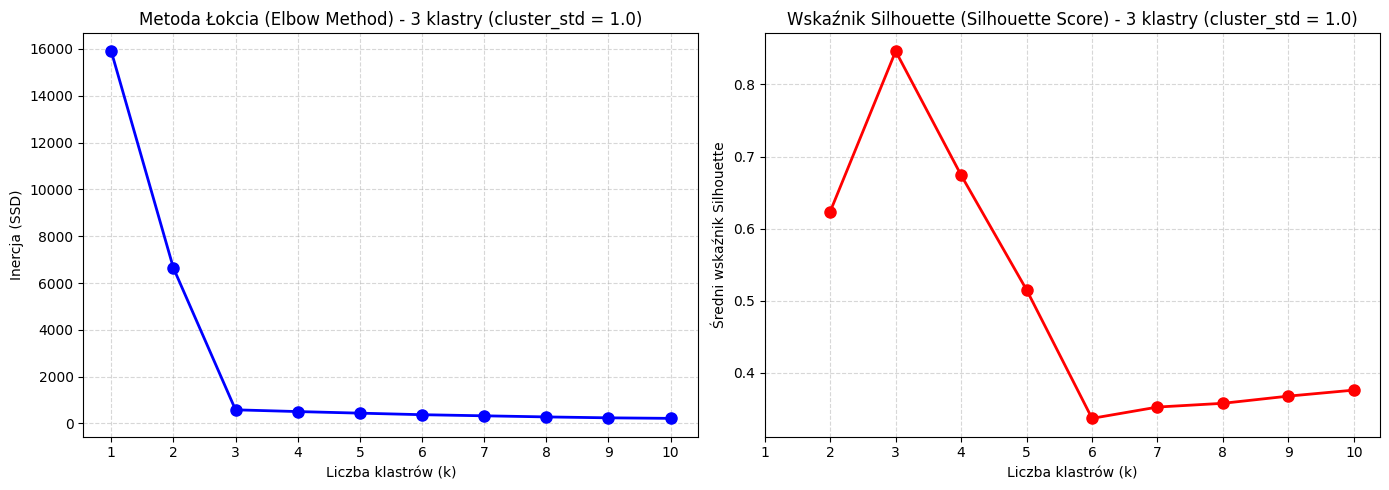

In [14]:
k_range = range(1, 11)
inertia_list = []
silhouette_list = []

for k in k_range:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = kmeans.fit_predict(X)
    inertia_list.append(kmeans.inertia_)
    if k > 1:
        silhouette_list.append(silhouette_score(X, labels))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(k_range, inertia_list, 'bo-', linewidth=2, markersize=8)
axes[0].set_title('Metoda Łokcia (Elbow Method) - 3 klastry (cluster_std = 1.0)')
axes[0].set_xlabel('Liczba klastrów (k)')
axes[0].set_ylabel('Inercja (SSD)')
axes[0].grid(True, linestyle='--', alpha=0.5)
axes[0].set_xticks(k_range)

axes[1].plot(k_range[1:], silhouette_list, 'ro-', linewidth=2, markersize=8)
axes[1].set_title('Wskaźnik Silhouette (Silhouette Score) - 3 klastry (cluster_std = 1.0)')
axes[1].set_xlabel('Liczba klastrów (k)')
axes[1].set_ylabel('Średni wskaźnik Silhouette')
axes[1].grid(True, linestyle='--', alpha=0.5)
axes[1].set_xticks(k_range)

plt.tight_layout()
plt.show()

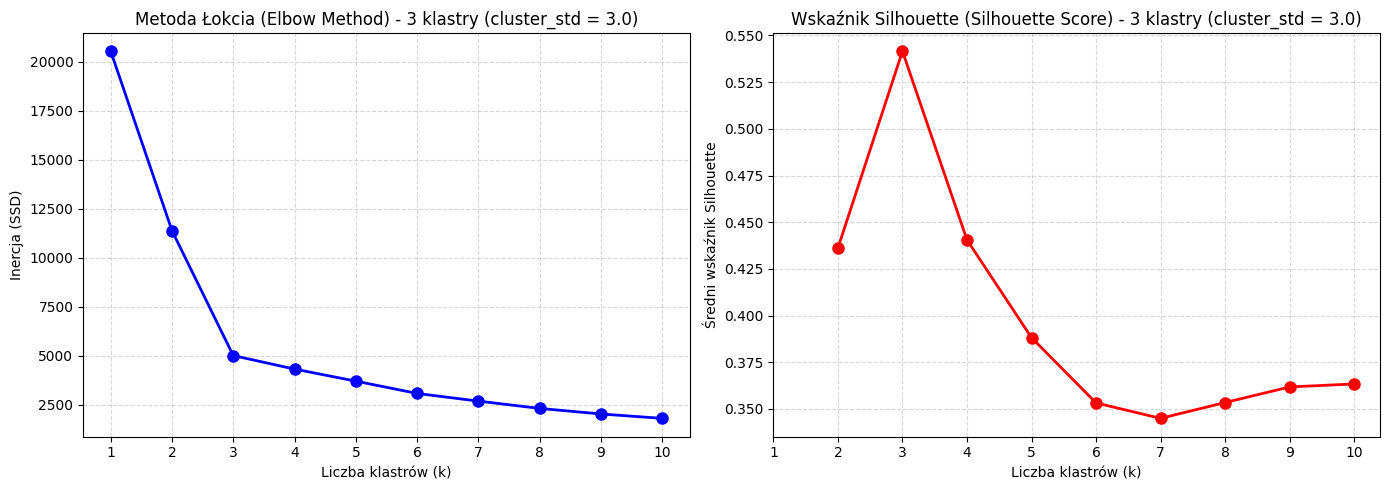

In [15]:
k_range = range(1, 11)
inertia_list = []
silhouette_list = []

for k in k_range:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = kmeans.fit_predict(X2)
    inertia_list.append(kmeans.inertia_)
    if k > 1:
        silhouette_list.append(silhouette_score(X2, labels))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(k_range, inertia_list, 'bo-', linewidth=2, markersize=8)
axes[0].set_title('Metoda Łokcia (Elbow Method) - 3 klastry (cluster_std = 3.0)')
axes[0].set_xlabel('Liczba klastrów (k)')
axes[0].set_ylabel('Inercja (SSD)')
axes[0].grid(True, linestyle='--', alpha=0.5)
axes[0].set_xticks(k_range)

axes[1].plot(k_range[1:], silhouette_list, 'ro-', linewidth=2, markersize=8)
axes[1].set_title('Wskaźnik Silhouette (Silhouette Score) - 3 klastry (cluster_std = 3.0)')
axes[1].set_xlabel('Liczba klastrów (k)')
axes[1].set_ylabel('Średni wskaźnik Silhouette')
axes[1].grid(True, linestyle='--', alpha=0.5)
axes[1].set_xticks(k_range)

plt.tight_layout()
plt.show()

## Zadanie 6

In [16]:
from sklearn.cluster import DBSCAN

def draw_dbscan(X, dbscan, ax):
    dbscan.fit(X)
    
    is_noise = dbscan.labels_ == -1

    ax.scatter(
        X[~is_noise, 0],
        X[~is_noise, 1],
        c=dbscan.labels_[~is_noise],
        cmap="Spectral",
        s=60,
        edgecolor="k",
        marker="o",
    )

    ax.scatter(
        X[is_noise, 0],
        X[is_noise, 1],
        color="black",
        marker="x",
        s=60,
        label="Szum / Outliery",
    )

    n_clusters = len(set(dbscan.labels_)) - (1 if -1 in dbscan.labels_ else 0)
    n_noise = list(dbscan.labels_).count(-1)

    ax.set_title(
        f"eps = {eps}, min_samples = {min_samples}\n(Klastry: {n_clusters}, Szum: {n_noise})", fontsize=12
    )
    ax.set_xlabel("X1")
    ax.set_ylabel("X2")
    ax.grid(True, linestyle="--", alpha=0.5)
    ax.legend(loc="best")

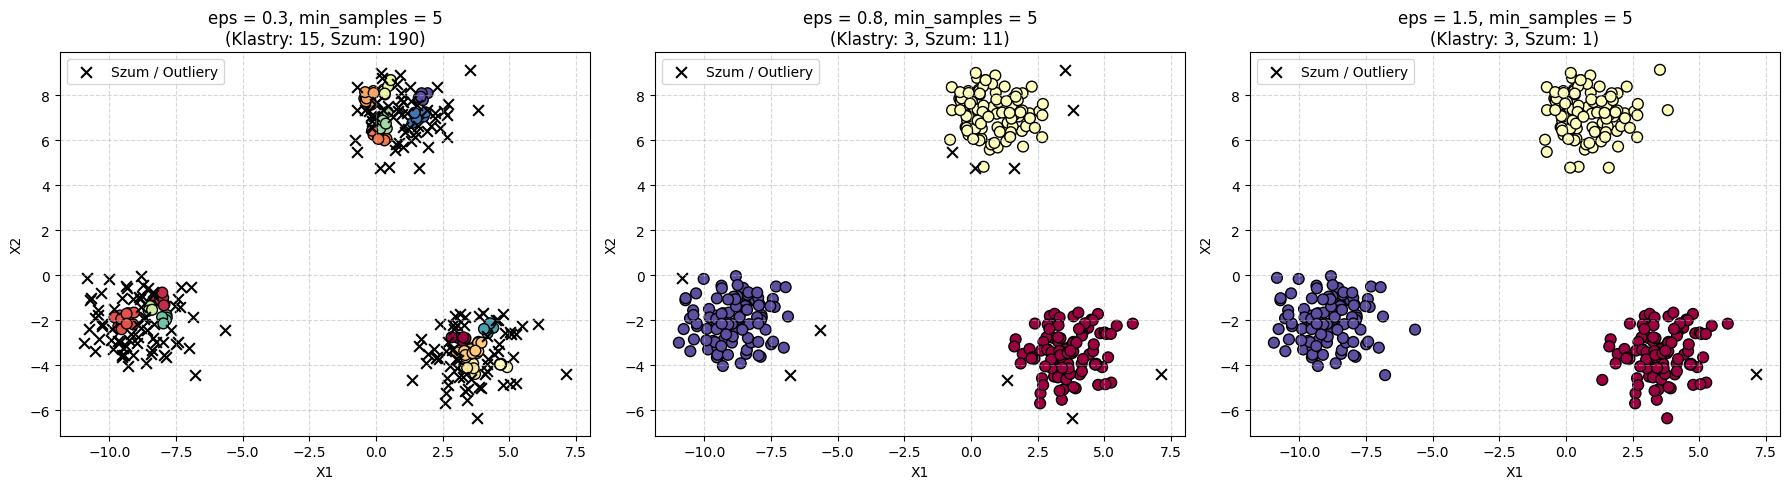

In [17]:
eps_values = [0.3, 0.8, 1.5]
min_samples = 5

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for i, eps in enumerate(eps_values):
    ax = axes[i]

    dbscan = DBSCAN(eps=eps, min_samples=min_samples)
    draw_dbscan(X, dbscan, ax)

plt.tight_layout()
plt.show()

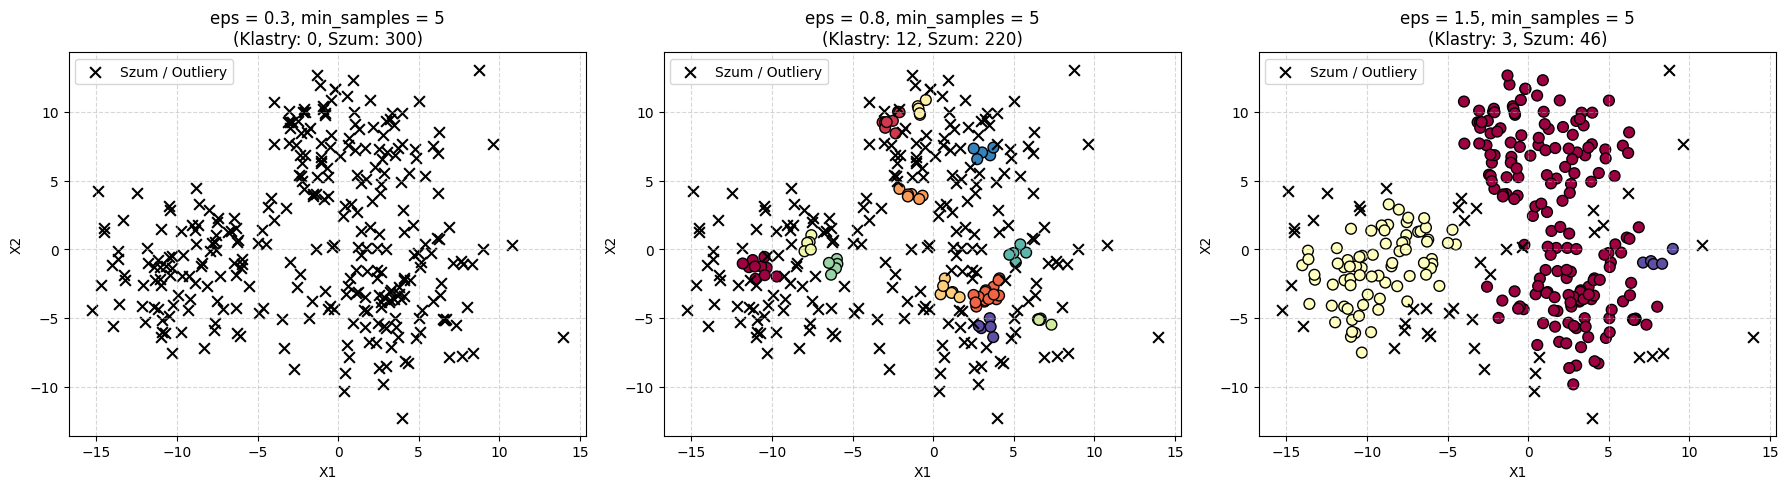

In [18]:
eps_values = [0.3, 0.8, 1.5]
min_samples = 5

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for i, eps in enumerate(eps_values):
    ax = axes[i]

    dbscan = DBSCAN(eps=eps, min_samples=min_samples)
    draw_dbscan(X2, dbscan, ax)

plt.tight_layout()
plt.show()

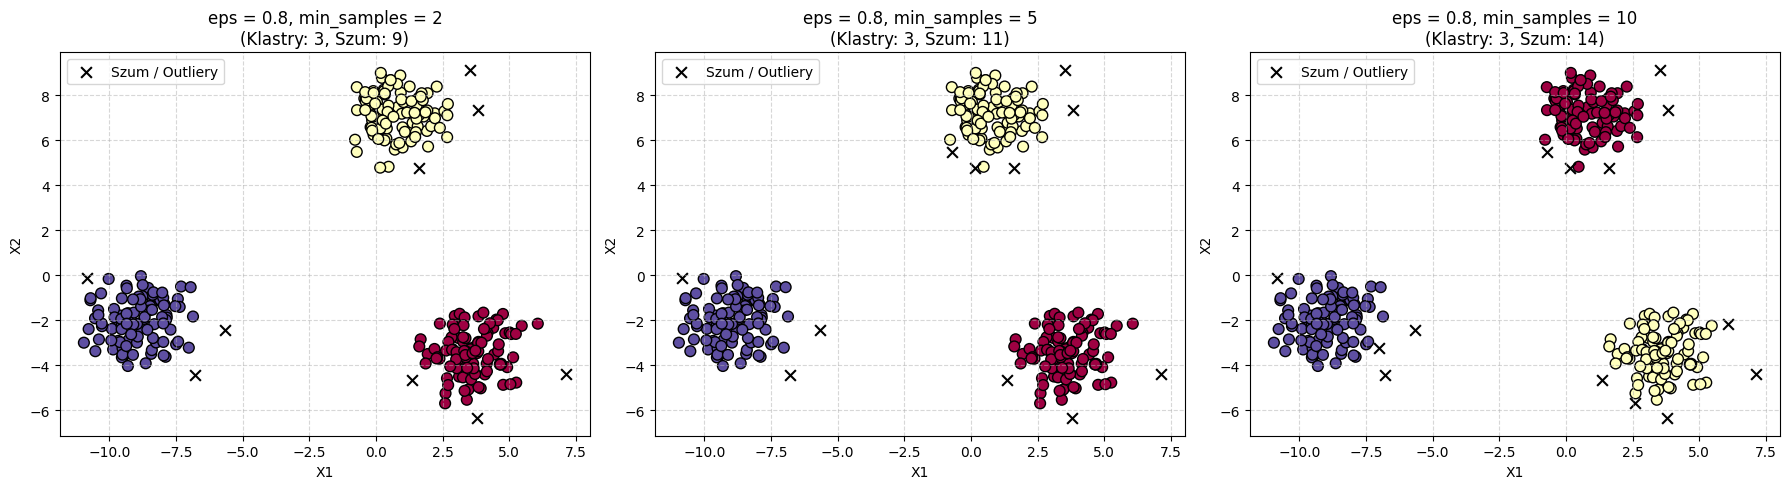

In [19]:
eps = 0.8
min_samples_values = [2, 5, 10]

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for i, min_samples in enumerate(min_samples_values):
    ax = axes[i]

    dbscan = DBSCAN(eps=eps, min_samples=min_samples)
    draw_dbscan(X, dbscan, ax)

plt.tight_layout()
plt.show()

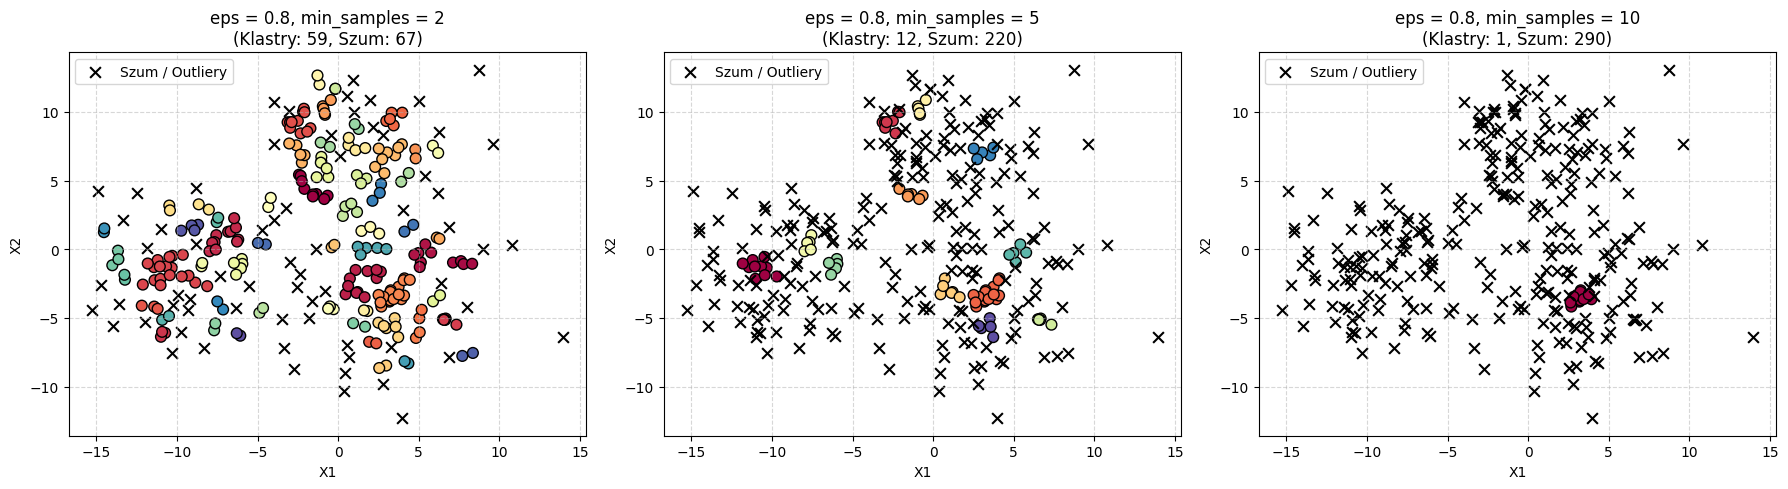

In [20]:
eps = 0.8
min_samples_values = [2, 5, 10]

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for i, min_samples in enumerate(min_samples_values):
    ax = axes[i]

    dbscan = DBSCAN(eps=eps, min_samples=min_samples)
    draw_dbscan(X2, dbscan, ax)

plt.tight_layout()
plt.show()

## Zadanie 7

In [21]:
import seaborn as sns
import kagglehub

path = kagglehub.dataset_download("vjchoudhary7/customer-segmentation-tutorial-in-python")

csv_file = os.path.join(path, "Mall_Customers.csv")
df = pd.read_csv(csv_file)

print(df.head())

   CustomerID  Gender  Age  Annual Income (k$)  Spending Score (1-100)
0           1    Male   19                  15                      39
1           2    Male   21                  15                      81
2           3  Female   20                  16                       6
3           4  Female   23                  16                      77
4           5  Female   31                  17                      40


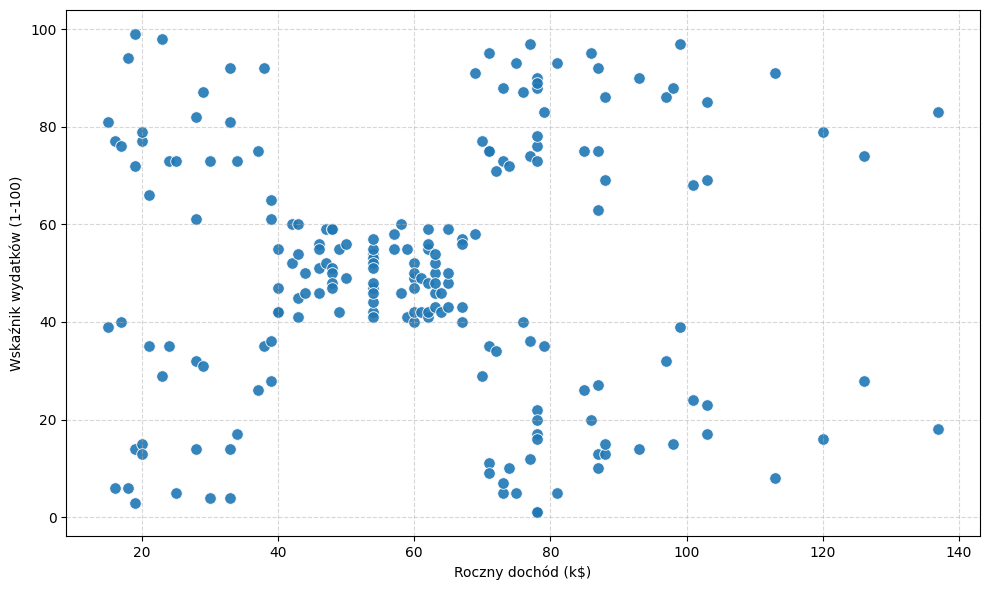

In [22]:
plt.figure(figsize=(10, 6))
sns.scatterplot(
    data=df, 
    x='Annual Income (k$)', 
    y='Spending Score (1-100)', 
    s=70, 
    alpha=0.9,
    legend=False
)

plt.xlabel('Roczny dochód (k$)')
plt.ylabel('Wskaźnik wydatków (1-100)')
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

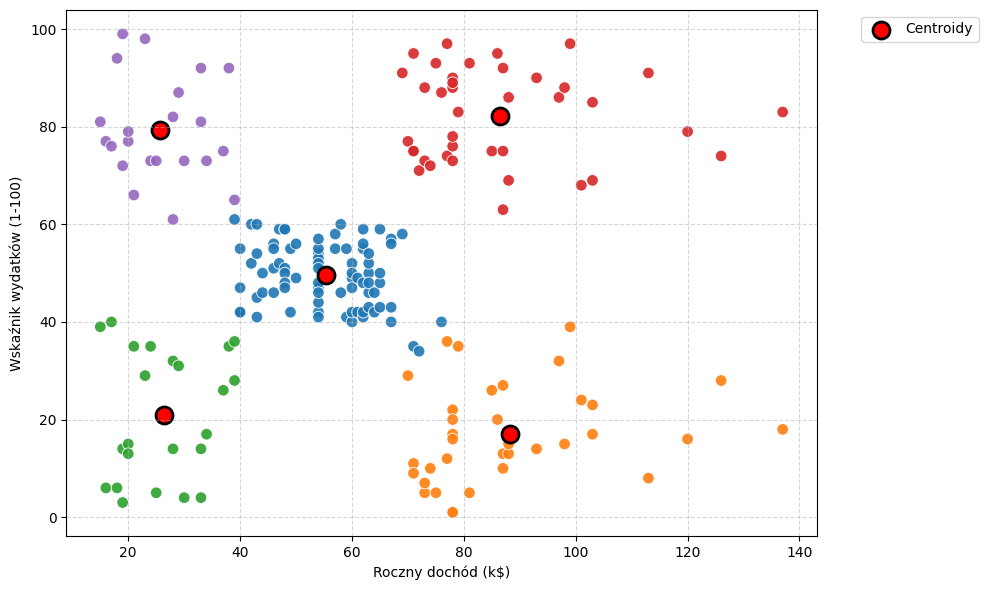

In [23]:
Xs = df[['Annual Income (k$)', 'Spending Score (1-100)']].values

kmeans = KMeans(n_clusters=5, random_state=67, n_init=10)
df['Cluster'] = kmeans.fit_predict(Xs)
centroids = kmeans.cluster_centers_

plt.figure(figsize=(10, 6))
sns.scatterplot(
    data=df, 
    x='Annual Income (k$)', 
    y='Spending Score (1-100)', 
    palette='tab10', 
    hue ='Cluster',
    s=70, 
    alpha=0.9,
    legend=False
)

plt.scatter(
    centroids[:, 0], 
    centroids[:, 1], 
    c='red', 
    s=150, 
    linewidths=2, 
    edgecolor='black', 
    label='Centroidy'
)

plt.xlabel('Roczny dochód (k$)')
plt.ylabel('Wskaźnik wydatków (1-100)')
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

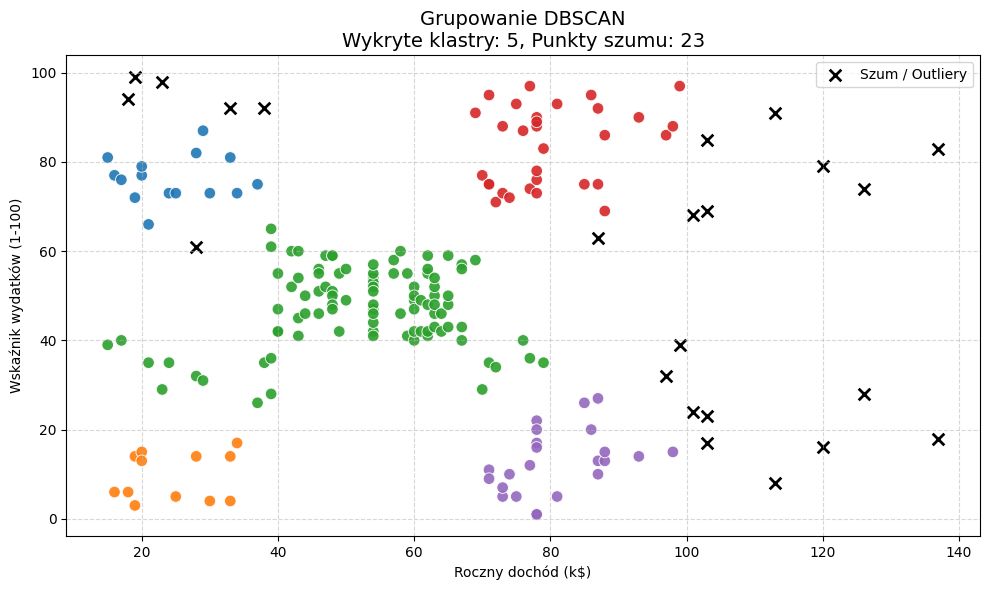

In [24]:
from sklearn.preprocessing import StandardScaler
X = df[["Annual Income (k$)", "Spending Score (1-100)"]].values

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

dbscan = DBSCAN(eps=0.38, min_samples=7)
df["Cluster"] = dbscan.fit_predict(X_scaled)


plt.figure(figsize=(10, 6))

is_noise = df["Cluster"] == -1

sns.scatterplot(
    data=df[~is_noise],
    x="Annual Income (k$)",
    y="Spending Score (1-100)",
    hue="Cluster",
    palette="tab10",
    s=70,
    alpha=0.9,
    legend=False,
)

plt.scatter(
    df.loc[is_noise, "Annual Income (k$)"],
    df.loc[is_noise, "Spending Score (1-100)"],
    color="black",
    marker="x",
    s=70,
    linewidths=2,
    label="Szum / Outliery",
)

n_clusters = len(set(df["Cluster"])) - (1 if -1 in df["Cluster"].values else 0)
n_noise = (df["Cluster"] == -1).sum()

plt.title(
    f"Grupowanie DBSCAN\nWykryte klastry: {n_clusters}, Punkty szumu: {n_noise}",
    fontsize=14,
)
plt.xlabel("Roczny dochód (k$)")
plt.ylabel("Wskaźnik wydatków (1-100)")
plt.grid(True, linestyle="--", alpha=0.5)
plt.legend(loc="upper right")

plt.tight_layout()
plt.show()